# Telco Customer Churn - Analysis, Modelling and SHAP

**Leakage-safe order of operations**

1. Clean data -> row-wise feature engineering (uses no learned statistics, so it is safe before the split)
2. 60 / 20 / 20 train / validation / test split
3. EDA on the **train** split only
4. Model selection and tuning with cross-validation on **train** only (all preprocessing / resampling inside the Pipeline)
5. Calibration and decision threshold chosen on **validation** only
6. **Test** set used once, at the end, for reporting

Requirements: `pandas numpy scikit-learn imbalanced-learn xgboost shap matplotlib seaborn joblib`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
import json
import warnings
from pathlib import Path
import joblib

warnings.filterwarnings("ignore", category=UserWarning)

## 1. Load and clean

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")  # updated: local path instead of Colab /content path

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Shape: (7043, 21)

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [9]:
# TotalCharges is sometimes read as string (raw Kaggle CSV has blank " " entries),
# sometimes already numeric depending on the source file. Handle both cases:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Blank/invalid TotalCharges converted to NaN:", df["TotalCharges"].isnull().sum())

# Sanity check: the blanks must be brand-new customers (tenure == 0) so filling with 0 is correct
assert (df.loc[df["TotalCharges"].isnull(), "tenure"] == 0).all()

Blank/invalid TotalCharges converted to NaN: 11


In [10]:
print(df["TotalCharges"].isnull().sum())

11


In [11]:
df[df["TotalCharges"].isnull()][
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [12]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [13]:
print(df["TotalCharges"].isnull().sum())

0


In [14]:
print(df["Churn"].value_counts())
print()
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [15]:
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

In [16]:
print(df["Churn"].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [17]:
df["customerID"].nunique()

7043

In [18]:
df = df.drop(columns=["customerID"])

In [19]:
print(df.shape)
print(df.columns.tolist())

(7043, 20)
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

## 2. Feature engineering (row-wise, leakage-safe)

- `num_services`, `is_autopay`, `avg_monthly_spend` are computed from the same row only.
- `gender` is dropped: it carries almost no signal and is a fairness risk when targeting retention offers.
- The helpers live in `churn_utils.py` (written below) so the Streamlit app uses **identical** code.

In [21]:
UTILS_SRC = r'''"""churn_utils.py - shared helpers (written by the notebook).
Training and the Streamlit app import THE SAME code, so features / calibration /
explanations can never drift apart."""
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

SERVICE_COLS = [
    "PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
]


def add_features(df):
    """Row-wise features only (no statistics learned from data -> no leakage)."""
    df = df.copy()
    df["num_services"] = (df[SERVICE_COLS] == "Yes").sum(axis=1)
    df["is_autopay"] = df["PaymentMethod"].str.contains("automatic", case=False).astype(int)
    avg = df["TotalCharges"] / df["tenure"].replace(0, np.nan)
    df["avg_monthly_spend"] = avg.fillna(df["MonthlyCharges"])
    return df


# --- Platt calibration (smooth; avoids the 0/1 steps isotonic gives on small data) ---
def _logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


def fit_calibrator(raw_scores, y_true):
    return LogisticRegression(C=1e6, max_iter=1000).fit(_logit(raw_scores), y_true)


def apply_calibration(calibrator, raw_scores):
    return calibrator.predict_proba(_logit(raw_scores))[:, 1]


# --- LLM-ready explanation payload (consumed by llm_explainer.py) ---
def _clean_value(v):
    if isinstance(v, (np.floating, float)):
        return round(float(v), 2)
    if isinstance(v, np.integer):
        return int(v)
    return v


def build_explanation(raw_row, score, threshold, shap_row, names, mapping, k=4):
    """SHAP is summed per ORIGINAL feature (signed), then described with the
    customer's actual value, e.g. 'Contract = Month-to-month' (strength: high)."""
    s = pd.Series(shap_row, index=list(names))
    by_feature = s.groupby(lambda n: mapping[n]).sum()
    top = float(by_feature.abs().max()) or 1.0

    def strength(v):
        a = abs(v) / top
        return "high" if a > 0.6 else "medium" if a > 0.25 else "low"

    def fmt(series):
        return [
            {"factor": f"{feat} = {_clean_value(raw_row[feat])}", "strength": strength(val)}
            for feat, val in series.items()
        ]

    return {
        "prediction": "Likely to churn" if score >= threshold else "Not likely to churn",
        "probability": float(score),   # calibrated RISK SCORE (not a guaranteed probability)
        "threshold": float(threshold),
        "top_factors_increasing": fmt(by_feature[by_feature > 0].sort_values(ascending=False).head(k)),
        "top_factors_reducing": fmt(by_feature[by_feature < 0].sort_values().head(k)),
    }
'''

Path("churn_utils.py").write_text(UTILS_SRC)

import importlib, churn_utils
importlib.reload(churn_utils)
from churn_utils import add_features, fit_calibrator, apply_calibration, build_explanation

df = add_features(df)
df = df.drop(columns=["gender"])

print(df.shape)
df[["num_services", "is_autopay", "avg_monthly_spend"]].describe().T

(7043, 22)


,count,mean,std,min,25%,50%,75%,max
num_services,7043.0,3.362914,2.062031,0.000,1.000000,3.0000,5.000000,8.0
is_autopay,7043.0,0.435326,0.495835,0.000,0.000000,0.0000,1.000000,1.0
avg_monthly_spend,7043.0,64.762906,30.189796,13.775,35.935156,70.3375,90.174158,121.4


## 3. Train / validation / test split (60 / 20 / 20)

Validation is used **only** for calibration and threshold selection. Test stays untouched until the final evaluation.

In [22]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

In [23]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 21)
y shape: (7043,)


In [24]:
print("Target distribution:")
print(y.value_counts(normalize=True))

Target distribution:
Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64


In [25]:
# Train / Validation / Test split (60% / 20% / 20%)
# Validation set is used strictly for business-threshold selection.
# Test set remains untouched until final evaluation.

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print("\nTrain churn rate:", y_train.mean())
print("Validation churn rate:", y_val.mean())
print("Test churn rate:", y_test.mean())

Training set: (4225, 21)
Validation set: (1409, 21)
Test set: (1409, 21)

Train churn rate: 0.26532544378698225
Validation churn rate: 0.2654364797728886
Test churn rate: 0.2654364797728886


In [26]:
# Verify class distributions across splits
split_summary = pd.DataFrame({
    "Set": ["Train", "Validation", "Test"],
    "Samples": [len(y_train), len(y_val), len(y_test)],
    "Churn Count": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "Churn Rate (%)": [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100]
})
print(split_summary.to_string(index=False))

       Set  Samples  Churn Count  Churn Rate (%)
     Train     4225         1121       26.532544
Validation     1409          374       26.543648
      Test     1409          374       26.543648

In [27]:
categorical_features = X.select_dtypes(
    include=["object", "string"]
).columns.tolist()

numerical_features = X.select_dtypes(
    exclude=["object", "string"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'num_services', 'is_autopay', 'avg_monthly_spend']


## 4. Exploratory data analysis (TRAIN split only)

EDA only ever sees the training rows, so nothing about validation / test can influence a decision.

In [28]:
train_df = X_train.assign(Churn=y_train)
print(train_df.shape)

(4225, 22)


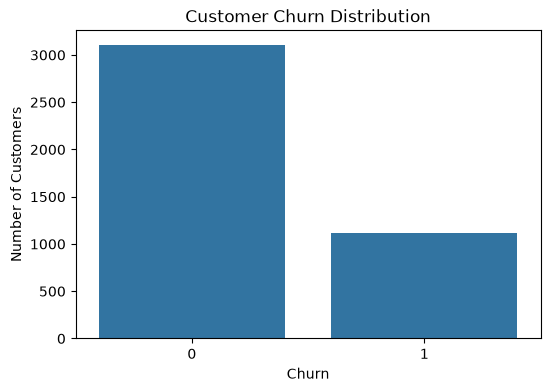

In [29]:
plt.figure(figsize=(6, 4))

sns.countplot(data=train_df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [30]:
churn_rate = train_df["Churn"].value_counts(normalize=True) * 100

print(churn_rate)

Churn
0    73.467456
1    26.532544
Name: proportion, dtype: float64


In [31]:
numeric_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "SeniorCitizen"
]

In [32]:
train_df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
tenure,4225.0,32.442840,24.629184,0.0,9.0,29.00,55.00,72.00
MonthlyCharges,4225.0,64.894509,30.326002,18.4,35.4,70.55,90.10,118.75
TotalCharges,4225.0,2295.489408,2287.797684,0.0,399.6,1372.45,3862.55,8684.80
SeniorCitizen,4225.0,0.161420,0.367962,0.0,0.0,0.00,0.00,1.00


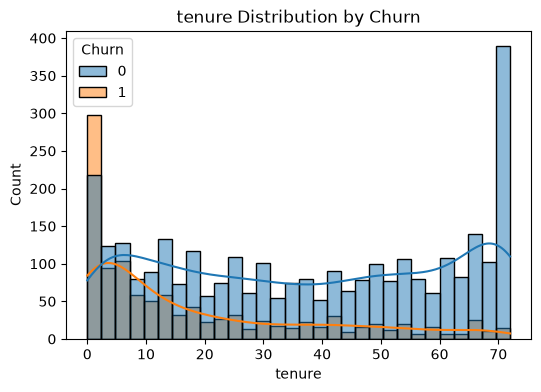

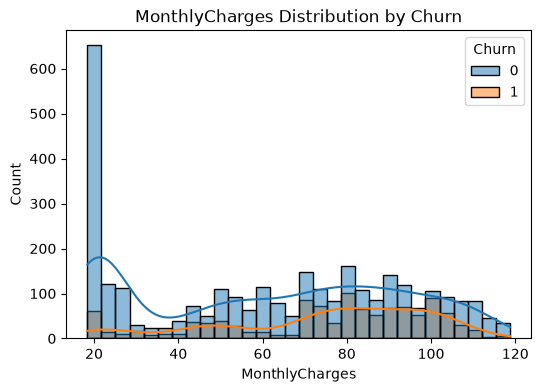

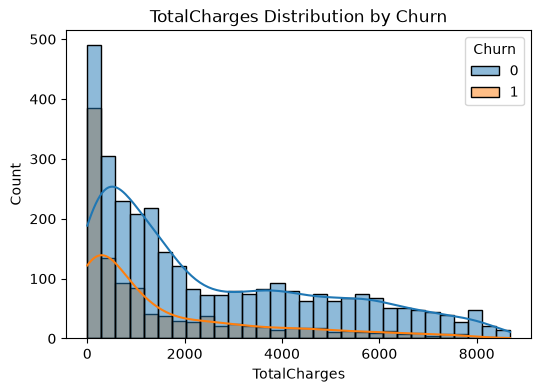

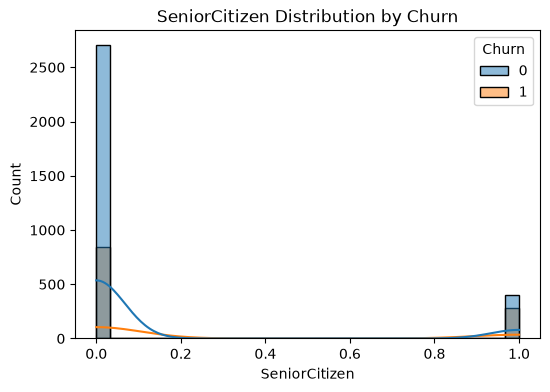

In [33]:
for col in numeric_cols:
    plt.figure(figsize=(6, 4))

    sns.histplot(
        data=train_df,
        x=col,
        hue="Churn",
        kde=True,
        bins=30
    )

    plt.title(f"{col} Distribution by Churn")
    plt.show()

In [34]:
train_df["tenure_group"] = pd.cut(
    train_df["tenure"],
    bins=[-1, 12, 24, 48, 60, 72],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49-60 months",
        "61-72 months"
    ]
)

In [35]:
tenure_churn = (
    train_df.groupby("tenure_group", observed=False)["Churn"]
      .mean()
      .mul(100)
)

print(tenure_churn)

tenure_group
0-12 months     47.723824
13-24 months    27.804878
25-48 months    19.682540
49-60 months    14.428858
61-72 months     7.429245
Name: Churn, dtype: float64


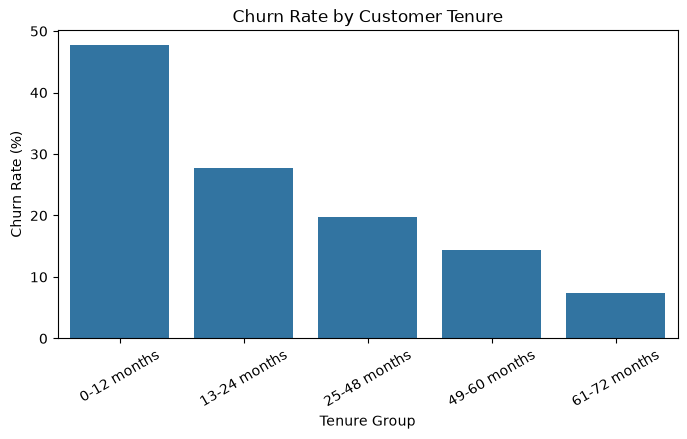

In [36]:
plt.figure(figsize=(8, 4))

sns.barplot(
    x=tenure_churn.index,
    y=tenure_churn.values
)

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30)

plt.show()

In [37]:
train_df["monthly_charge_group"] = pd.cut(
    train_df["MonthlyCharges"],
    bins=[0, 30, 60, 90, 120, np.inf],
    labels=[
        "0-30",
        "31-60",
        "61-90",
        "91-120",
        "120+"
    ]
)

In [38]:
charge_churn = (
    train_df.groupby("monthly_charge_group", observed=False)["Churn"]
      .mean()
      .mul(100)
)

print(charge_churn)

monthly_charge_group
0-30       9.700000
31-60     26.145553
61-90     33.239437
91-120    33.678269
120+            NaN
Name: Churn, dtype: float64


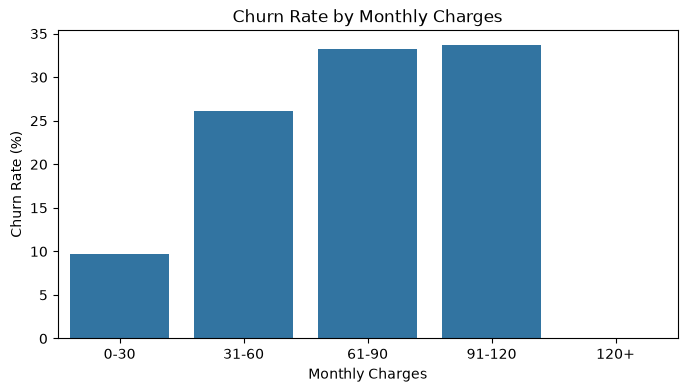

In [39]:
plt.figure(figsize=(8, 4))

sns.barplot(
    x=charge_churn.index,
    y=charge_churn.values
)

plt.title("Churn Rate by Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Churn Rate (%)")

plt.show()

In [40]:
categorical_cols = X_train.select_dtypes(include=["object", "string"]).columns.tolist()

print(categorical_cols)

['Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [41]:
for col in categorical_cols:

    churn_rate = (
        train_df.groupby(col)["Churn"]
          .mean()
          .sort_values(ascending=False)
          .mul(100)
    )

    print(f"\n===== {col} =====")
    print(churn_rate)


===== Partner =====
Partner
No     32.968037
Yes    19.606880
Name: Churn, dtype: float64

===== Dependents =====
Dependents
No     31.534570
Yes    14.761905
Name: Churn, dtype: float64

===== PhoneService =====
PhoneService
Yes    26.869588
No     23.429952
Name: Churn, dtype: float64

===== MultipleLines =====
MultipleLines
Yes                 28.795518
No                  25.172754
No phone service    23.429952
Name: Churn, dtype: float64

===== InternetService =====
InternetService
Fiber optic    41.904250
DSL            19.080780
No              7.311828
Name: Churn, dtype: float64

===== OnlineSecurity =====
OnlineSecurity
No                     42.112880
Yes                    14.729951
No internet service     7.311828
Name: Churn, dtype: float64

===== OnlineBackup =====
OnlineBackup
No                     40.395170
Yes                    21.520706
No internet service     7.311828
Name: Churn, dtype: float64

===== DeviceProtection =====
DeviceProtection
No                   

In [42]:
important_cats = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity",
    "PaperlessBilling"
]

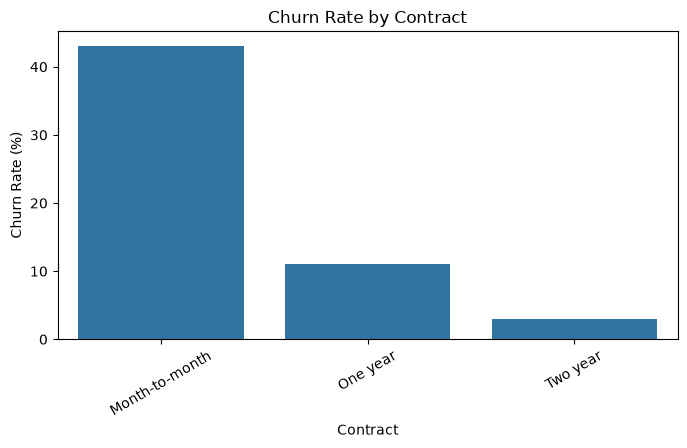

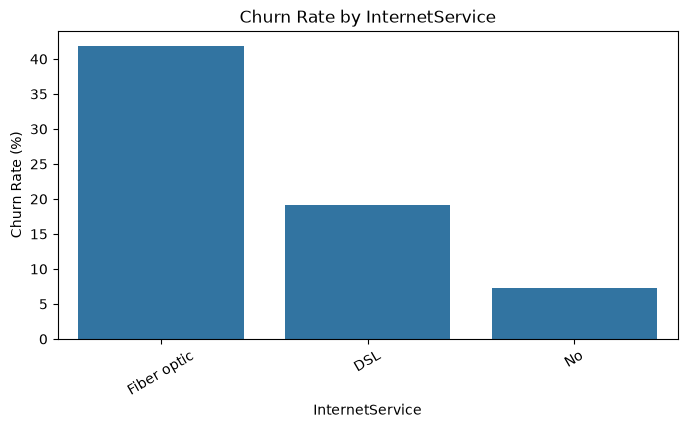

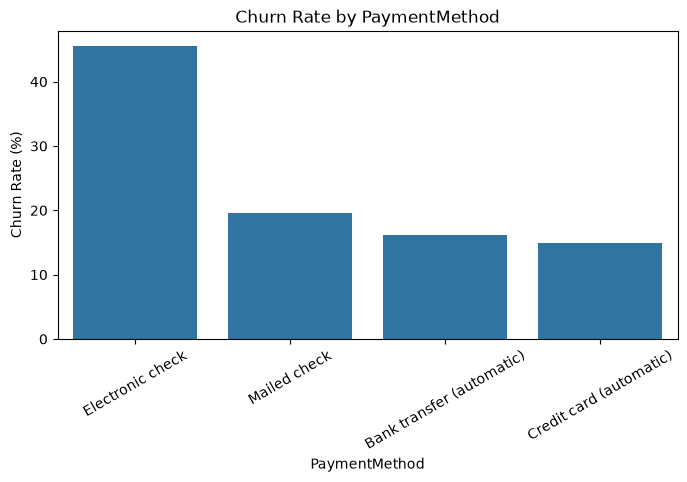

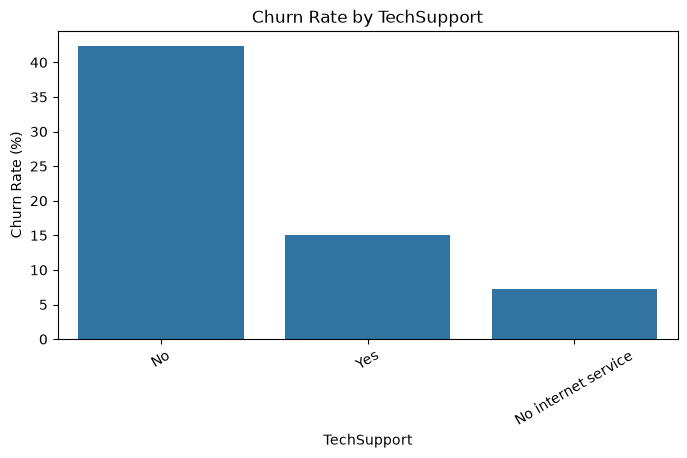

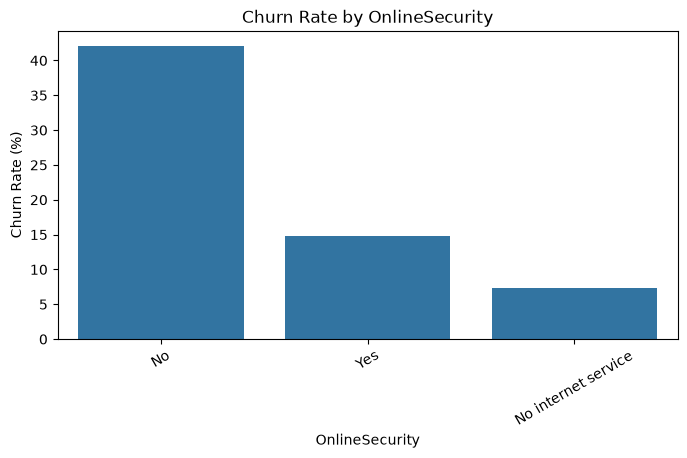

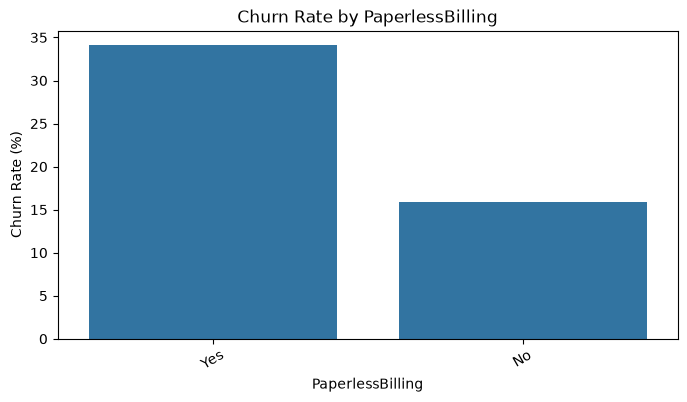

In [43]:
for col in important_cats:

    churn_rate = (
        train_df.groupby(col)["Churn"]
          .mean()
          .mul(100)
          .sort_values(ascending=False)
    )

    plt.figure(figsize=(8, 4))

    sns.barplot(
        x=churn_rate.index,
        y=churn_rate.values
    )

    plt.title(f"Churn Rate by {col}")
    plt.xlabel(col)
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=30)

    plt.show()

In [44]:
contract_churn = (
    train_df.groupby("Contract")["Churn"]
      .agg(["count", "mean"])
)

contract_churn["churn_rate"] = contract_churn["mean"] * 100

contract_churn = contract_churn.drop(columns="mean")

print(contract_churn)

                count  churn_rate
Contract                         
Month-to-month   2304   43.055556
One year          896   11.049107
Two year         1025    2.926829


In [45]:
profile = train_df.groupby("Churn")[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].mean()

print(profile)

          tenure  MonthlyCharges  TotalCharges
Churn                                         
0      37.545103       61.293750   2558.701579
1      18.314897       74.864853   1566.666414


In [46]:
profile_median = train_df.groupby("Churn")[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].median()

print(profile_median)

       tenure  MonthlyCharges  TotalCharges
Churn                                      
0        38.0            64.4        1672.1
1        10.0            80.0         692.1


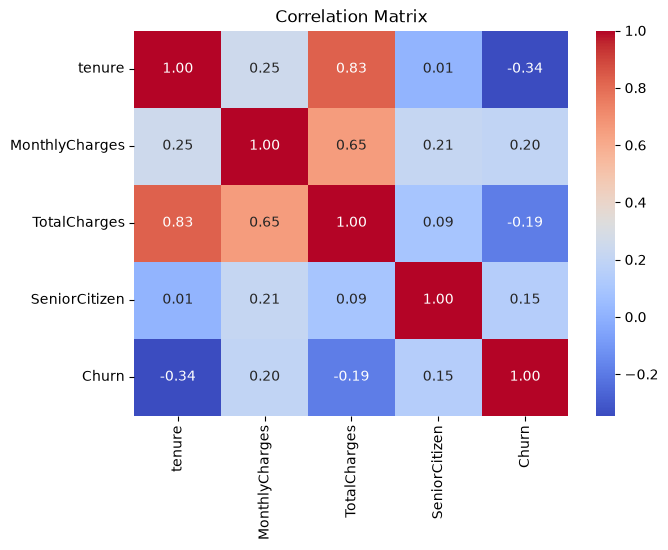

In [47]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    train_df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn"]]
    .corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()

### Headline insights and revenue at risk

The numbers below are computed from the data (nothing hard-coded). In the interview, turn each into one sentence: *segment -> churn rate -> what the business should do*.

In [48]:
overall = train_df["Churn"].mean() * 100
print(f"Overall churn rate (train): {overall:.1f}%\n")

for contract in ["Month-to-month", "One year", "Two year"]:
    r = train_df.loc[train_df["Contract"] == contract, "Churn"].mean() * 100
    print(f"  {contract:<15}: {r:5.1f}% churn")

seg_mask = (
    (train_df["Contract"] == "Month-to-month")
    & (train_df["InternetService"] == "Fiber optic")
    & (train_df["TechSupport"] == "No")
)
print(f"\nMonth-to-month + Fiber + no TechSupport: {train_df.loc[seg_mask, 'Churn'].mean() * 100:.1f}% churn "
      f"({seg_mask.sum()} customers) vs {overall:.1f}% overall")

new = train_df["tenure"] <= 12
print(f"Customers in first 12 months: {train_df.loc[new, 'Churn'].mean() * 100:.1f}% churn "
      f"vs {train_df.loc[~new, 'Churn'].mean() * 100:.1f}% after")

Overall churn rate (train): 26.5%

  Month-to-month :  43.1% churn
  One year       :  11.0% churn
  Two year       :   2.9% churn

Month-to-month + Fiber + no TechSupport: 57.4% churn (1078 customers) vs 26.5% overall
Customers in first 12 months: 47.7% churn vs 16.9% after


In [49]:
segments = (
    train_df.assign(rev_at_risk=train_df["MonthlyCharges"] * train_df["Churn"])
    .groupby(["Contract", "InternetService"])
    .agg(
        customers=("Churn", "size"),
        churn_rate_pct=("Churn", lambda s: s.mean() * 100),
        monthly_revenue_at_risk=("rev_at_risk", "sum"),
    )
    .sort_values("monthly_revenue_at_risk", ascending=False)
    .round(1)
)
segments

customers  churn_rate_pct  \
Contract       InternetService                              
Month-to-month Fiber optic           1274            55.0   
               DSL                    717            32.4   
One year       Fiber optic            331            18.1   
               DSL                    337             9.8   
Two year       Fiber optic            254             7.1   
Month-to-month No                     313            18.8   
Two year       DSL                    382             2.4   
One year       No                     228             2.6   
Two year       No                     389             0.8   

                                monthly_revenue_at_risk  
Contract       InternetService                           
Month-to-month Fiber optic                      61025.0  
               DSL                              10906.8  
One year       Fiber optic                       6131.2  
               DSL                               1976.6  
Two year       Fiber optic                       1903.3  
Month-to-month No                                1195.6  
Two year       DSL                                590.4  
One year       No                                 130.7  
Two year       No                                  63.8

## 5. Preprocessing and baseline models (cross-validation on TRAIN)

In [50]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [51]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

In [52]:
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [53]:
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

In [54]:
from sklearn.model_selection import StratifiedKFold, cross_validate

In [55]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [56]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

In [57]:
cv_results = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [58]:
for metric in scoring.keys():
    scores = cv_results[f"test_{metric}"]

    print(
        f"{metric.upper():10s}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

ACCURACY  : 0.7496 ± 0.0116
PRECISION : 0.5187 ± 0.0145
RECALL    : 0.7886 ± 0.0402
F1        : 0.6254 ± 0.0181
ROC_AUC   : 0.8437 ± 0.0183
PR_AUC    : 0.6579 ± 0.0476


In [59]:
logistic_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](21,)","['SeniorCitizen','Partner','Dependents',...,'num_services','is_autopay', 'avg_monthly_spend']"
n_features_in_,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [60]:
y_proba_logistic = logistic_pipeline.predict_proba(
    X_test
)[:, 1]

In [61]:
y_pred_logistic = (
    y_proba_logistic >= 0.5
).astype(int)

In [62]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

In [63]:
print("=== Logistic Regression Baseline ===")

print(
    classification_report(
        y_test,
        y_pred_logistic,
        digits=4
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic))

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_proba_logistic)
)

print(
    "PR-AUC:",
    average_precision_score(y_test, y_proba_logistic)
)

=== Logistic Regression Baseline ===
              precision    recall  f1-score   support

           0     0.9109    0.7208    0.8047      1035
           1     0.5102    0.8048    0.6245       374

    accuracy                         0.7431      1409
   macro avg     0.7105    0.7628    0.7146      1409
weighted avg     0.8045    0.7431    0.7569      1409

Confusion Matrix:
[[746 289]
 [ 73 301]]
ROC-AUC: 0.830966958588442
PR-AUC: 0.6182151414246512


In [64]:
from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    (
        "model",
        RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        )
    )
])

In [65]:
rf_cv_results = cross_validate(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [66]:
random_forest_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](21,)","['SeniorCitizen','Partner','Dependents',...,'num_services','is_autopay', 'avg_monthly_spend']"
n_features_in_,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [67]:
y_proba_rf = random_forest_pipeline.predict_proba(
    X_test
)[:, 1]

In [68]:
y_pred_rf = (
    y_proba_rf >= 0.5
).astype(int)

In [69]:
print("=== Random Forest ===")

print(
    classification_report(
        y_test,
        y_pred_rf,
        digits=4
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_proba_rf)
)

print(
    "PR-AUC:",
    average_precision_score(y_test, y_proba_rf)
)

=== Random Forest ===
              precision    recall  f1-score   support

           0     0.8262    0.8773    0.8510      1035
           1     0.5903    0.4893    0.5351       374

    accuracy                         0.7743      1409
   macro avg     0.7083    0.6833    0.6930      1409
weighted avg     0.7636    0.7743    0.7671      1409

Confusion Matrix:
[[908 127]
 [191 183]]
ROC-AUC: 0.8034953111679455
PR-AUC: 0.583509797034683


In [70]:
from xgboost import XGBClassifier

In [71]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    (
        "model",
        XGBClassifier(
            n_estimators=300,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )
    )
])

In [72]:
xgb_cv_results = cross_validate(
    xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [73]:
for metric in scoring.keys():
    scores = xgb_cv_results[f"test_{metric}"]

    print(
        f"{metric.upper():10s}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

ACCURACY  : 0.7960 ± 0.0129
PRECISION : 0.6347 ± 0.0351
RECALL    : 0.5495 ± 0.0203
F1        : 0.5885 ± 0.0207
ROC_AUC   : 0.8382 ± 0.0090
PR_AUC    : 0.6478 ± 0.0116


In [74]:
xgb_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](21,)","['SeniorCitizen','Partner','Dependents',...,'num_services','is_autopay', 'avg_monthly_spend']"
n_features_in_,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [75]:
y_proba_xgb = xgb_pipeline.predict_proba(
    X_test
)[:, 1]

y_pred_xgb = (
    y_proba_xgb >= 0.5
).astype(int)

In [76]:
print("=== XGBoost ===")

print(
    classification_report(
        y_test,
        y_pred_xgb,
        digits=4
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_proba_xgb)
)

print(
    "PR-AUC:",
    average_precision_score(
        y_test,
        y_proba_xgb
    )
)

=== XGBoost ===
              precision    recall  f1-score   support

           0     0.8290    0.8715    0.8497      1035
           1     0.5857    0.5027    0.5410       374

    accuracy                         0.7736      1409
   macro avg     0.7074    0.6871    0.6954      1409
weighted avg     0.7644    0.7736    0.7678      1409

Confusion Matrix:
[[902 133]
 [186 188]]
ROC-AUC: 0.8137267818853496
PR-AUC: 0.6049933640855066


### SMOTE vs class weighting

SMOTE on one-hot columns creates fractional dummy values, and the threshold is tuned anyway. Compare it with plain class weighting using the **same** CV folds and pick the winner by PR-AUC.

In [77]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_weighted_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        XGBClassifier(
            n_estimators=300,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=pos_weight,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )
    )
])

xgb_weighted_cv = cross_validate(
    xgb_weighted_pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1
)

pr_smote = xgb_cv_results["test_pr_auc"].mean()
pr_weight = xgb_weighted_cv["test_pr_auc"].mean()

print(f"XGBoost + SMOTE            CV PR-AUC: {pr_smote:.4f}")
print(f"XGBoost + class weighting  CV PR-AUC: {pr_weight:.4f}")

use_smote = pr_smote > pr_weight
print("\nTuning the", "SMOTE" if use_smote else "class-weighted", "pipeline.")

XGBoost + SMOTE            CV PR-AUC: 0.6478
XGBoost + class weighting  CV PR-AUC: 0.6573

Tuning the class-weighted pipeline.


## 6. Hyperparameter tuning (TRAIN only, PR-AUC)

In [78]:
from sklearn.model_selection import RandomizedSearchCV

In [79]:
# Pipeline matches the winner of the SMOTE-vs-weights comparison above.
# Everything (encoding, resampling) is fitted inside each CV fold -> no leakage.
steps = [("preprocessor", preprocessor)]

if use_smote:
    steps.append(("smote", SMOTE(random_state=42)))

steps.append((
    "model",
    XGBClassifier(
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
        scale_pos_weight=1.0 if use_smote else pos_weight
    )
))

xgb_tuning_pipeline = Pipeline(steps)

In [80]:
param_distributions = {
    "model__n_estimators": [100, 200, 300, 400, 500],

    "model__max_depth": [3, 4, 5, 6, 7],

    "model__learning_rate": [
        0.01,
        0.03,
        0.05,
        0.1,
        0.15
    ],

    "model__min_child_weight": [
        1,
        3,
        5,
        7
    ],

    "model__subsample": [
        0.6,
        0.7,
        0.8,
        0.9,
        1.0
    ],

    "model__colsample_bytree": [
        0.6,
        0.7,
        0.8,
        0.9,
        1.0
    ],

    "model__gamma": [
        0,
        0.1,
        0.3,
        0.5
    ],

    "model__reg_alpha": [
        0,
        0.01,
        0.1,
        1
    ],

    "model__reg_lambda": [
        1,
        1.5,
        2,
        5
    ]
}

In [81]:
xgb_random_search = RandomizedSearchCV(
    estimator=xgb_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=1,
    return_train_score=False
)

In [82]:
xgb_random_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__colsample_bytree': [0.6, 0.7, ...], 'model__gamma': [0, 0.1, ...], 'model__learning_rate': [0.01, 0.03, ...], 'model__max_depth': [3, 4, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoo

In [83]:
print("Best PR-AUC:")
print(xgb_random_search.best_score_)

Best PR-AUC:
0.6737759398737818


In [84]:
print("\nBest Parameters:")
print(xgb_random_search.best_params_)


Best Parameters:
{'model__subsample': 0.9, 'model__reg_lambda': 5, 'model__reg_alpha': 0.01, 'model__n_estimators': 500, 'model__min_child_weight': 1, 'model__max_depth': 4, 'model__learning_rate': 0.01, 'model__gamma': 0.5, 'model__colsample_bytree': 0.6}


In [85]:
best_xgb_model = xgb_random_search.best_estimator_

## 7. Model evaluation on TEST (threshold-free comparison + 0.50 report)

In [86]:
# RAW scores from the final tuned XGBoost pipeline (calibrated in the next section)
# Validation probabilities are used for threshold selection.
# Test probabilities are reserved for final evaluation.

y_proba_val = best_xgb_model.predict_proba(
    X_val
)[:, 1]

y_proba_tuned = best_xgb_model.predict_proba(
    X_test
)[:, 1]

# Standard 0.50 predictions on the untouched test set
y_pred_tuned = (
    y_proba_tuned >= 0.5
).astype(int)

In [87]:
print("=== Tuned XGBoost ===")

print(
    classification_report(
        y_test,
        y_pred_tuned,
        digits=4
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_tuned
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        y_proba_tuned
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y_test,
        y_proba_tuned
    )
)

=== Tuned XGBoost ===
              precision    recall  f1-score   support

           0     0.9111    0.7324    0.8120      1035
           1     0.5199    0.8021    0.6309       374

    accuracy                         0.7509      1409
   macro avg     0.7155    0.7673    0.7215      1409
weighted avg     0.8072    0.7509    0.7639      1409

Confusion Matrix:
[[758 277]
 [ 74 300]]
ROC-AUC: 0.8326616549122944
PR-AUC: 0.62802559510683


In [88]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "XGBoost (default)", "XGBoost (tuned)"],
    "ROC-AUC": [roc_auc_score(y_test, p) for p in [y_proba_logistic, y_proba_rf, y_proba_xgb, y_proba_tuned]],
    "PR-AUC": [average_precision_score(y_test, p) for p in [y_proba_logistic, y_proba_rf, y_proba_xgb, y_proba_tuned]],
}).round(4)

comparison

,Model,ROC-AUC,PR-AUC
0,Logistic Regression,0.8310,0.6182
1,Random Forest,0.8035,0.5835
2,XGBoost (default),0.8137,0.6050
3,XGBoost (tuned),0.8327,0.6280


> **Say this in the interview:** if tuned XGBoost is only marginally better than (or equal to) logistic regression, state it plainly. XGBoost is kept for non-linear effects and SHAP; in production the simpler model would be a defensible choice.

## 8. Calibration (VALIDATION set)

Class weighting / SMOTE shifts predicted scores, so the raw output is **not** a true probability. A Platt calibrator is fitted on the validation set; from here on the output is called a **risk score**. The calibration is monotonic, so ranking (ROC-AUC / PR-AUC) is unchanged.

Brier score on TEST - raw: 0.1671 -> calibrated: 0.1412


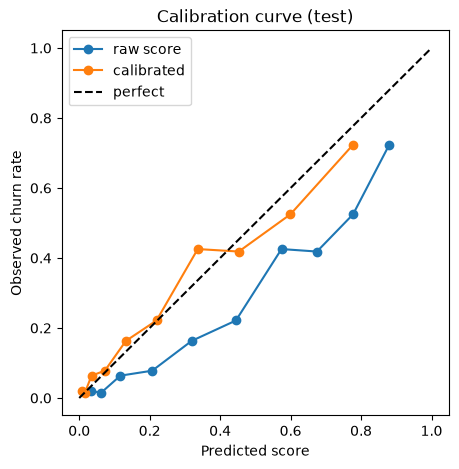

In [89]:
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve

calibrator = fit_calibrator(y_proba_val, y_val)

p_val_cal = apply_calibration(calibrator, y_proba_val)
p_test_cal = apply_calibration(calibrator, y_proba_tuned)

print(f"Brier score on TEST - raw: {brier_score_loss(y_test, y_proba_tuned):.4f} "
      f"-> calibrated: {brier_score_loss(y_test, p_test_cal):.4f}")

plt.figure(figsize=(5, 5))
for label, p in [("raw score", y_proba_tuned), ("calibrated", p_test_cal)]:
    frac, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    plt.plot(mean_pred, frac, marker="o", label=label)
plt.plot([0, 1], [0, 1], "k--", label="perfect")
plt.xlabel("Predicted score")
plt.ylabel("Observed churn rate")
plt.title("Calibration curve (test)")
plt.legend()
plt.show()

## 9. Decision threshold (VALIDATION only)

In [90]:
from sklearn.metrics import precision_score, recall_score, f1_score

# F1 threshold analysis is performed on the validation set,
# not the final test set.
thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        p_val_cal >= threshold
    ).astype(int)

    precision = precision_score(
        y_val,
        y_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_pred_threshold,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        y_pred_threshold,
        zero_division=0
    )

    threshold_results.append({
        "threshold": round(threshold, 2),
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df)

    threshold  precision    recall        f1
0        0.05   0.363908  0.975936  0.530138
1        0.06   0.374486  0.973262  0.540862
2        0.07   0.385928  0.967914  0.551829
3        0.08   0.393209  0.959893  0.557887
4        0.09   0.401345  0.957219  0.565561
..        ...        ...       ...       ...
86       0.91   0.000000  0.000000  0.000000
87       0.92   0.000000  0.000000  0.000000
88       0.93   0.000000  0.000000  0.000000
89       0.94   0.000000  0.000000  0.000000
90       0.95   0.000000  0.000000  0.000000

[91 rows x 4 columns]


In [91]:
best_f1_row = threshold_df.loc[
    threshold_df["f1"].idxmax()
]

print("Best F1 Threshold:")
print(best_f1_row)

Best F1 Threshold:
threshold    0.390000
precision    0.619048
recall       0.695187
f1           0.654912
Name: 34, dtype: float64


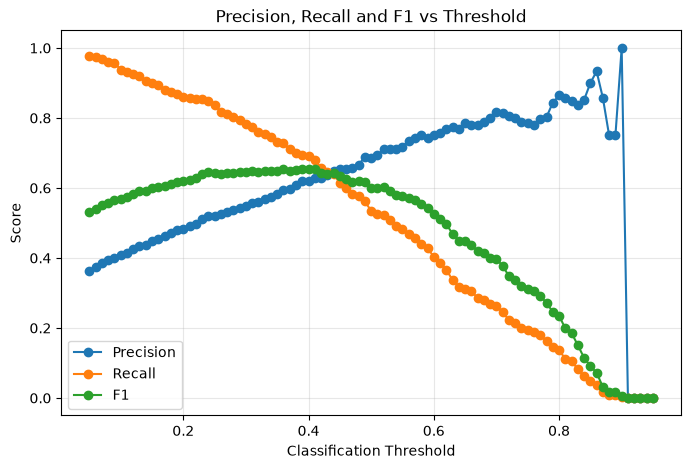

In [92]:
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    marker="o",
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs Threshold")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Business assumptions -> expected net value

These numbers are **assumptions**, not measured data - state that in the interview and show the sensitivity table below.

Net value = (saved churners x save rate x customer value) - (customers flagged x offer cost). The offer cost is paid for **every** flagged customer, including the true positives.

In [93]:
# ============================================================
# BUSINESS ASSUMPTIONS (change these to match your story)
# ============================================================
CUSTOMER_VALUE = 2500        # INR value retained if a churner is saved
OFFER_COST = 500             # INR cost of one retention offer (paid for every flagged customer)
BASE_SAVE_RATE = 0.40        # share of flagged churners the offer actually retains
SAVE_RATE_SCENARIOS = [0.20, 0.30, 0.40, 0.50, 1.00]

# Legacy FP/FN view from the earlier version (kept for comparison only)
COST_FALSE_POSITIVE = 500
COST_FALSE_NEGATIVE = 2500


def net_value(y_true, flagged, save_rate):
    y_true = np.asarray(y_true)
    flagged = np.asarray(flagged, dtype=bool)
    tp = int((flagged & (y_true == 1)).sum())
    return tp * save_rate * CUSTOMER_VALUE - int(flagged.sum()) * OFFER_COST


def legacy_cost(y_true, flagged):
    y_true = np.asarray(y_true)
    flagged = np.asarray(flagged, dtype=bool)
    fp = int((flagged & (y_true == 0)).sum())
    fn = int((~flagged & (y_true == 1)).sum())
    return fp * COST_FALSE_POSITIVE + fn * COST_FALSE_NEGATIVE

In [94]:
# ============================================================
# THRESHOLD SEARCH ON THE VALIDATION SET (calibrated risk scores)
# ============================================================
value_results = []

for threshold in thresholds:
    flagged = p_val_cal >= threshold
    tn, fp, fn, tp = confusion_matrix(y_val, flagged.astype(int), labels=[0, 1]).ravel()

    value_results.append({
        "threshold": round(float(threshold), 2),
        "flagged": int(flagged.sum()),
        "TP": tp, "FP": fp, "FN": fn,
        "net_value": net_value(y_val, flagged, BASE_SAVE_RATE)
    })

value_df = pd.DataFrame(value_results)

print(f"Top 10 thresholds by validation net value (save rate = {BASE_SAVE_RATE:.0%}):")
print(value_df.sort_values("net_value", ascending=False).head(10).to_string(index=False))

Top 10 thresholds by validation net value (save rate = 40%):
 threshold  flagged  TP  FP  FN  net_value
      0.52      276 196  80 178    58000.0
      0.49      305 210  95 164    57500.0
      0.53      267 190  77 184    56500.0
      0.56      238 175  63 199    56000.0
      0.57      230 171  59 203    56000.0
      0.44      368 239 129 135    55000.0
      0.51      284 197  87 177    55000.0
      0.55      252 181  71 193    55000.0
      0.58      220 165  55 209    55000.0
      0.54      259 184  75 190    54500.0


In [95]:
best_value_row = value_df.loc[value_df["net_value"].idxmax()]
best_business_threshold = float(best_value_row["threshold"])

print("Best business threshold (validation):")
print(best_value_row)

Best business threshold (validation):
threshold        0.52
flagged        276.00
TP             196.00
FP              80.00
FN             178.00
net_value    58000.00
Name: 47, dtype: float64


In [96]:
# Sensitivity: how does the best threshold move if the save rate is different?
rows = []
for sr in SAVE_RATE_SCENARIOS:
    vals = [net_value(y_val, p_val_cal >= t, sr) for t in thresholds]
    i = int(np.argmax(vals))
    rows.append({
        "save_rate": sr,
        "best_threshold": float(thresholds[i]),
        "validation_net_value_INR": round(vals[i])
    })

sensitivity_df = pd.DataFrame(rows)
print(sensitivity_df.to_string(index=False))
print("\nIf net value is 0 the campaign is not profitable at any threshold under that save rate.")

 save_rate  best_threshold  validation_net_value_INR
       0.2            0.90                         0
       0.3            0.58                     13750
       0.4            0.52                     58000
       0.5            0.41                    115500
       1.0            0.24                    487500

If net value is 0 the campaign is not profitable at any threshold under that save rate.


In [97]:
# ============================================================
# VALIDATION PERFORMANCE AT THE SELECTED BUSINESS THRESHOLD
# ============================================================

y_pred_val_business = (
    p_val_cal >= best_business_threshold
).astype(int)

print(
    f"\n===== Validation: Business Threshold "
    f"{best_business_threshold:.2f} ====="
)

print(
    classification_report(
        y_val,
        y_pred_val_business,
        digits=4,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_val,
        y_pred_val_business
    )
)

# Standard 0.50 validation comparison
y_pred_val_050 = (
    p_val_cal >= 0.50
).astype(int)

print("\n===== Validation: Standard Threshold 0.50 =====")

print(
    classification_report(
        y_val,
        y_pred_val_050,
        digits=4,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_val,
        y_pred_val_050
    )
)


===== Validation: Business Threshold 0.52 =====
              precision    recall  f1-score   support

           0     0.8429    0.9227    0.8810      1035
           1     0.7101    0.5241    0.6031       374

    accuracy                         0.8169      1409
   macro avg     0.7765    0.7234    0.7420      1409
weighted avg     0.8077    0.8169    0.8072      1409

Confusion Matrix:
[[955  80]
 [178 196]]

===== Validation: Standard Threshold 0.50 =====
              precision    recall  f1-score   support

           0     0.8442    0.9111    0.8764      1035
           1     0.6849    0.5348    0.6006       374

    accuracy                         0.8112      1409
   macro avg     0.7646    0.7229    0.7385      1409
weighted avg     0.8019    0.8112    0.8032      1409

Confusion Matrix:
[[943  92]
 [174 200]]


## 10. SHAP explainability

In [98]:
import shap  # pip install shap
import matplotlib.pyplot as plt

C:\Users\infom\OneDrive\Desktop\gouse\customer_churn_2\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [99]:
xgb_model = best_xgb_model.named_steps["model"]

In [100]:
fitted_preprocessor = best_xgb_model.named_steps["preprocessor"]

In [101]:
X_test_transformed = fitted_preprocessor.transform(X_test)

In [102]:
feature_names = fitted_preprocessor.get_feature_names_out()

print(len(feature_names))
print(feature_names)

46
['categorical__Partner_No' 'categorical__Partner_Yes'
 'categorical__Dependents_No' 'categorical__Dependents_Yes'
 'categorical__PhoneService_No' 'categorical__PhoneService_Yes'
 'categorical__MultipleLines_No'
 'categorical__MultipleLines_No phone service'
 'categorical__MultipleLines_Yes' 'categorical__InternetService_DSL'
 'categorical__InternetService_Fiber optic'
 'categorical__InternetService_No' 'categorical__OnlineSecurity_No'
 'categorical__OnlineSecurity_No internet service'
 'categorical__OnlineSecurity_Yes' 'categorical__OnlineBackup_No'
 'categorical__OnlineBackup_No internet service'
 'categorical__OnlineBackup_Yes' 'categorical__DeviceProtection_No'
 'categorical__DeviceProtection_No internet service'
 'categorical__DeviceProtection_Yes' 'categorical__TechSupport_No'
 'categorical__TechSupport_No internet service'
 'categorical__TechSupport_Yes' 'categorical__StreamingTV_No'
 'categorical__StreamingTV_No internet service'
 'categorical__StreamingTV_Yes' 'categorical__

In [103]:
import shap

explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(X_test_transformed)

if isinstance(shap_values, list):      # older SHAP versions return one array per class
    shap_values = shap_values[1]

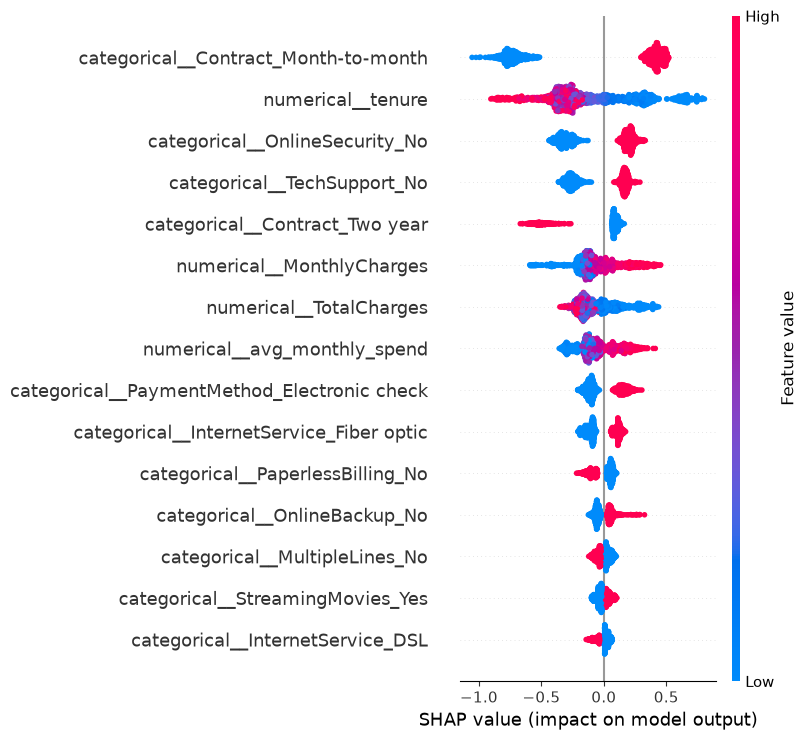

In [104]:
shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
    max_display=15
)

In [105]:
# Map each transformed column (e.g. categorical__Contract_Month-to-month) back to its original feature
cat_cols_fitted = fitted_preprocessor.transformers_[0][2]

feature_mapping = {}

for name in feature_names:
    if name.startswith("numerical__"):
        feature_mapping[str(name)] = name[len("numerical__"):]
    else:
        rest = name[len("categorical__"):]
        # longest column name first so similarly-named columns can never collide
        for col in sorted(cat_cols_fitted, key=len, reverse=True):
            if rest.startswith(col + "_"):
                feature_mapping[str(name)] = col
                break

assert len(feature_mapping) == len(feature_names), "Some transformed features were not mapped"

# FIX: sum the SIGNED SHAP values of a feature's dummies FIRST, then take the absolute value.
# (Summing abs() per dummy inflated multi-category features such as Contract / PaymentMethod.)
shap_df = pd.DataFrame(shap_values, columns=[str(n) for n in feature_names])

groups = {}
for transformed, original in feature_mapping.items():
    groups.setdefault(original, []).append(transformed)

aggregated_shap = pd.DataFrame({
    original: shap_df[cols].sum(axis=1) for original, cols in groups.items()
})

shap_importance = aggregated_shap.abs().mean().sort_values(ascending=False)

print(shap_importance)

Contract             0.729534
tenure               0.328213
OnlineSecurity       0.267937
TechSupport          0.223004
InternetService      0.158106
MonthlyCharges       0.153501
TotalCharges         0.141368
avg_monthly_spend    0.141284
PaymentMethod        0.140787
PaperlessBilling     0.112168
OnlineBackup         0.067775
MultipleLines        0.058059
StreamingMovies      0.049788
Dependents           0.043959
is_autopay           0.030482
SeniorCitizen        0.028809
num_services         0.009852
PhoneService         0.008384
Partner              0.006298
StreamingTV          0.005342
DeviceProtection     0.004313
dtype: float32


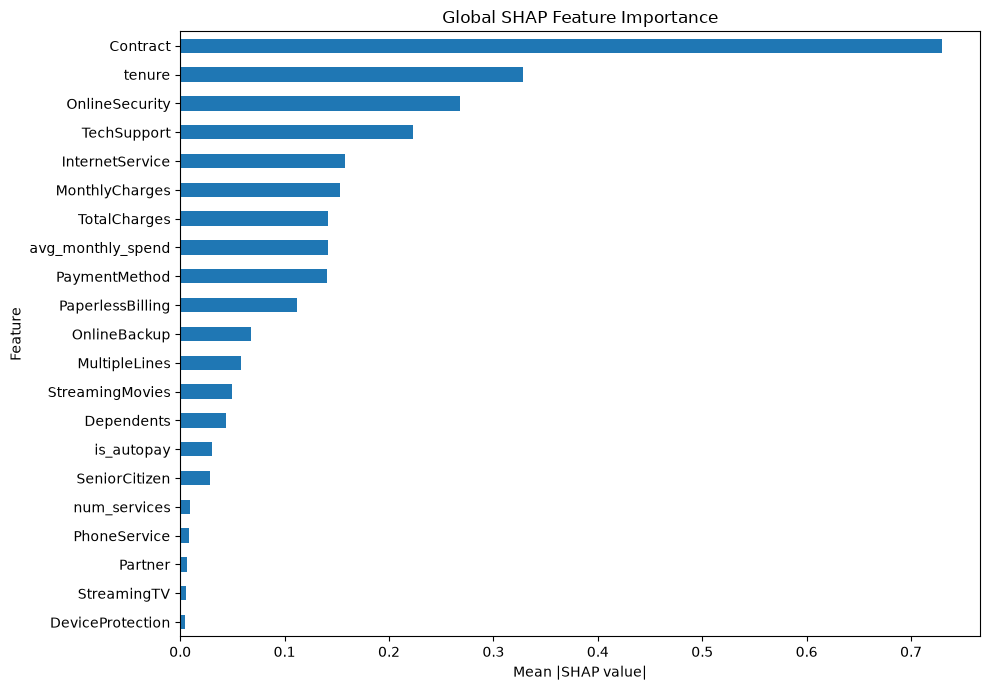

In [106]:
plt.figure(figsize=(10, 7))

shap_importance.sort_values().plot(
    kind="barh"
)

plt.xlabel("Mean |SHAP value|")
plt.ylabel("Feature")
plt.title("Global SHAP Feature Importance")
plt.tight_layout()

plt.show()

In [107]:
shap_importance_df = (
    shap_importance
    .reset_index()
)

shap_importance_df.columns = [
    "Feature",
    "Mean_Absolute_SHAP"
]

print(shap_importance_df)

              Feature  Mean_Absolute_SHAP
0            Contract            0.729534
1              tenure            0.328213
2      OnlineSecurity            0.267937
3         TechSupport            0.223004
4     InternetService            0.158106
5      MonthlyCharges            0.153501
6        TotalCharges            0.141368
7   avg_monthly_spend            0.141284
8       PaymentMethod            0.140787
9    PaperlessBilling            0.112168
10       OnlineBackup            0.067775
11      MultipleLines            0.058059
12    StreamingMovies            0.049788
13         Dependents            0.043959
14         is_autopay            0.030482
15      SeniorCitizen            0.028809
16       num_services            0.009852
17       PhoneService            0.008384
18            Partner            0.006298
19        StreamingTV            0.005342
20   DeviceProtection            0.004313


> SHAP values are in **log-odds** and explain the *model*, not the real world - they show association, not causation.

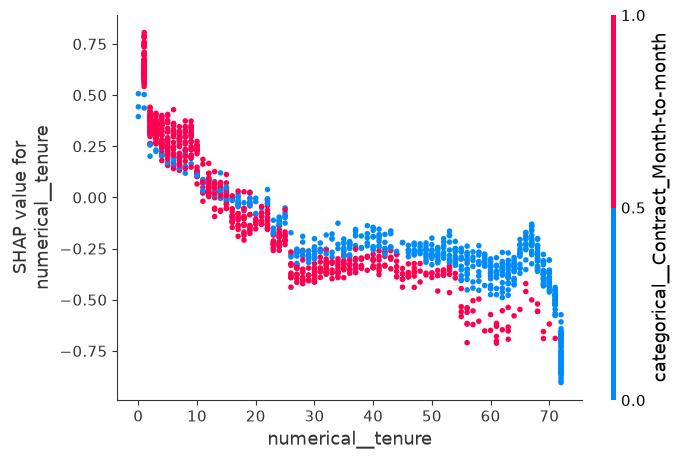

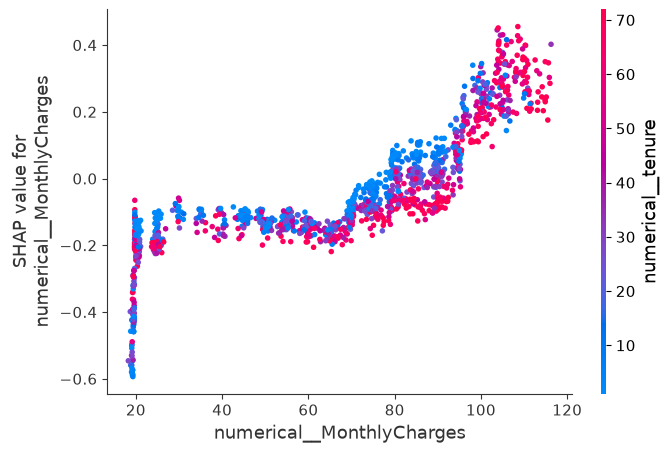

In [108]:
for feat in ["numerical__tenure", "numerical__MonthlyCharges"]:
    shap.dependence_plot(feat, shap_values, X_test_transformed, feature_names=feature_names)

In [109]:
# Select the highest-risk customer according to the FINAL tuned model.
high_risk_idx = np.argmax(y_proba_tuned)

print("Index:", high_risk_idx)
print("Risk score (calibrated):", p_test_cal[high_risk_idx])
print("Actual churn:", y_test.iloc[high_risk_idx])

Index: 391
Risk score (calibrated): 0.9070649420754062
Actual churn: 1


In [110]:
print(
    "Risk score (calibrated):",
    p_test_cal[high_risk_idx]
)
print(X_test.iloc[high_risk_idx])

Risk score (calibrated): 0.9070649420754062
SeniorCitizen                       1
Partner                            No
Dependents                         No
tenure                              1
PhoneService                      Yes
MultipleLines                     Yes
InternetService           Fiber optic
OnlineSecurity                     No
OnlineBackup                       No
DeviceProtection                   No
TechSupport                        No
StreamingTV                       Yes
StreamingMovies                   Yes
Contract               Month-to-month
PaperlessBilling                  Yes
PaymentMethod        Electronic check
MonthlyCharges                   94.0
TotalCharges                     94.0
num_services                        4
is_autopay                          0
avg_monthly_spend                94.0
Name: 4800, dtype: object


In [111]:
customer_idx = high_risk_idx

customer_shap = shap_values[customer_idx]
customer_data = X_test_transformed[customer_idx]

In [112]:
customer_explanation = shap.Explanation(
    values=customer_shap,
    base_values=explainer.expected_value,
    data=customer_data,
    feature_names=feature_names
)

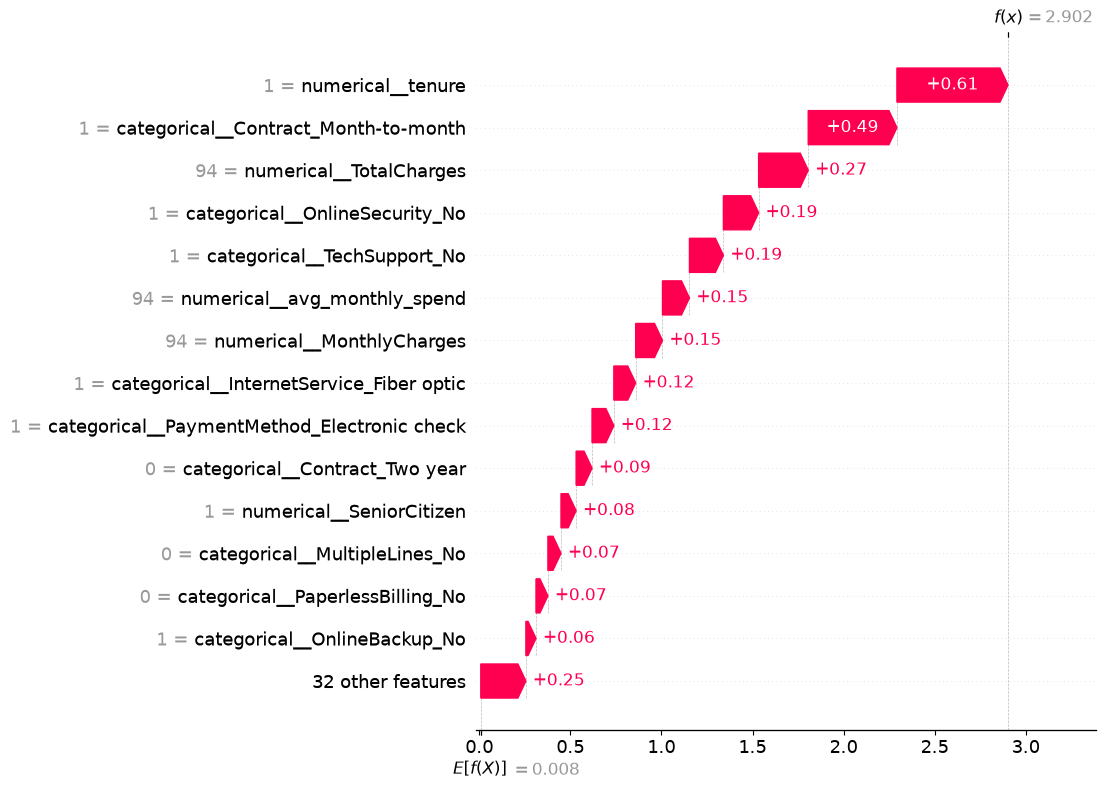

In [113]:
shap.plots.waterfall(customer_explanation, max_display=15)

In [114]:
customer_contributions = pd.DataFrame({
    "Feature": feature_names,
    "SHAP_Value": customer_shap
})

customer_contributions["Impact"] = np.where(
    customer_contributions["SHAP_Value"] > 0,
    "Increases Churn",
    "Decreases Churn"
)

customer_contributions["Abs_SHAP"] = (
    customer_contributions["SHAP_Value"].abs()
)

customer_contributions = (
    customer_contributions
    .sort_values("Abs_SHAP", ascending=False)
)

print(customer_contributions.head(15).to_string(index=False))

                                    Feature  SHAP_Value          Impact  Abs_SHAP
                          numerical__tenure    0.609769 Increases Churn  0.609769
       categorical__Contract_Month-to-month    0.486910 Increases Churn  0.486910
                    numerical__TotalCharges    0.272288 Increases Churn  0.272288
             categorical__OnlineSecurity_No    0.193368 Increases Churn  0.193368
                categorical__TechSupport_No    0.186351 Increases Churn  0.186351
               numerical__avg_monthly_spend    0.148079 Increases Churn  0.148079
                  numerical__MonthlyCharges    0.147096 Increases Churn  0.147096
   categorical__InternetService_Fiber optic    0.119925 Increases Churn  0.119925
categorical__PaymentMethod_Electronic check    0.119768 Increases Churn  0.119768
             categorical__Contract_Two year    0.087317 Increases Churn  0.087317
                   numerical__SeniorCitizen    0.083056 Increases Churn  0.083056
              ca

In [115]:
# Payload for the LLM explanation layer (llm_explainer.py)
explanation = build_explanation(
    raw_row=X_test.iloc[high_risk_idx],
    score=float(p_test_cal[high_risk_idx]),
    threshold=best_business_threshold,
    shap_row=customer_shap,
    names=[str(n) for n in feature_names],
    mapping=feature_mapping,
)

print(json.dumps(explanation, indent=2))

{
  "prediction": "Likely to churn",
  "probability": 0.9070649420754062,
  "threshold": 0.52,
  "top_factors_increasing": [
    {
      "factor": "tenure = 1",
      "strength": "high"
    },
    {
      "factor": "Contract = Month-to-month",
      "strength": "high"
    },
    {
      "factor": "TotalCharges = 94.0",
      "strength": "medium"
    },
    {
      "factor": "OnlineSecurity = No",
      "strength": "medium"
    }
  ],
  "top_factors_reducing": [
    {
      "factor": "PhoneService = Yes",
      "strength": "low"
    },
    {
      "factor": "Partner = No",
      "strength": "low"
    }
  ]
}


## 11. FINAL TEST evaluation (threshold locked on validation, test used once)

In [116]:
# The threshold was selected ONLY on the validation set (calibrated scores).
# It is now locked and evaluated once on the untouched test set.
y_pred_final = (p_test_cal >= best_business_threshold).astype(int)

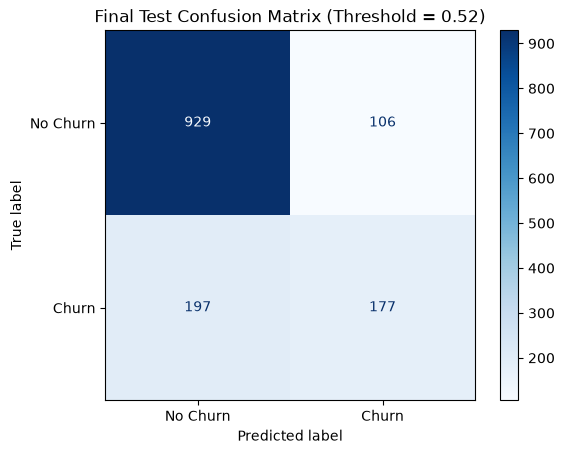

In [117]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred_final
)

tn, fp, fn, tp = cm.ravel()

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues")
plt.title(
    f"Final Test Confusion Matrix "
    f"(Threshold = {best_business_threshold:.2f})"
)
plt.show()

In [118]:
from sklearn.metrics import classification_report

print("=== FINAL TEST PERFORMANCE ===")

print(
    classification_report(
        y_test,
        y_pred_final,
        digits=4,
        zero_division=0
    )
)

=== FINAL TEST PERFORMANCE ===
              precision    recall  f1-score   support

           0     0.8250    0.8976    0.8598      1035
           1     0.6254    0.4733    0.5388       374

    accuracy                         0.7850      1409
   macro avg     0.7252    0.6854    0.6993      1409
weighted avg     0.7721    0.7850    0.7746      1409



In [119]:
flagged_final = y_pred_final.astype(bool)

print(f"Locked threshold: {best_business_threshold:.2f}")
print(f"TN: {tn} | FP: {fp} | FN: {fn} | TP: {tp}")
print(f"Precision: {tp / (tp + fp):.3f} | Recall: {tp / (tp + fn):.3f}")
print(f"\nExpected net value at save rate {BASE_SAVE_RATE:.0%}: "
      f"INR {net_value(y_test, flagged_final, BASE_SAVE_RATE):,.0f}")

Locked threshold: 0.52
TN: 929 | FP: 106 | FN: 197 | TP: 177
Precision: 0.625 | Recall: 0.473

Expected net value at save rate 40%: INR 35,500


In [120]:
# Strategy comparison on the test set (same assumptions for every strategy)
at_050 = p_test_cal >= 0.50
everyone = np.ones(len(y_test), dtype=bool)
nobody = np.zeros(len(y_test), dtype=bool)

strategy_df = pd.DataFrame({
    "strategy": ["Model @ locked threshold", "Model @ 0.50", "Flag everyone", "Flag nobody"],
    "customers_flagged": [int(flagged_final.sum()), int(at_050.sum()), int(everyone.sum()), 0],
    f"net_value_INR (save rate {BASE_SAVE_RATE:.0%})": [
        round(net_value(y_test, f, BASE_SAVE_RATE)) for f in [flagged_final, at_050, everyone, nobody]
    ],
    "legacy_FP_FN_cost_INR": [
        legacy_cost(y_test, f) for f in [flagged_final, at_050, everyone, nobody]
    ],
})

strategy_df

,strategy,customers_flagged,net_value_INR (save rate 40%),legacy_FP_FN_cost_INR
0,Model @ locked threshold,283,35500,545500
1,Model @ 0.50,305,39500,511500
2,Flag everyone,1409,-330500,517500
3,Flag nobody,0,0,935000


        customers  churners  cum_churners_captured_%  lift
decile                                                    
1             141       102                    27.27  2.73
2             141        74                    47.06  2.35
3             141        59                    62.83  2.09
4             141        60                    78.88  1.97
5             141        31                    87.17  1.74
6             141        23                    93.32  1.56
7             141        11                    96.26  1.38
8             141         9                    98.66  1.23
9             141         2                    99.20  1.10
10            140         3                   100.00  1.00

The top 20% highest-risk customers capture 47% of all churners.


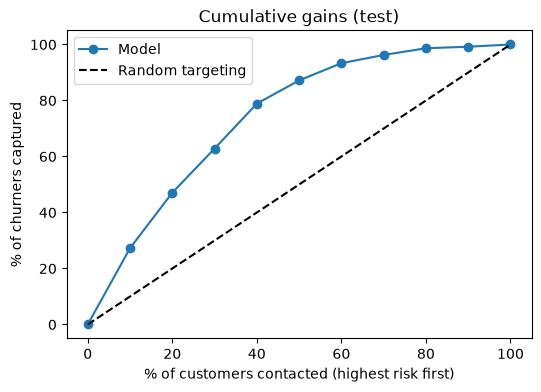

In [121]:
# Gains / lift by risk decile (ranking uses the raw model score; calibration is monotonic)
def gains_table(y_true, score, n_bins=10):
    d = (
        pd.DataFrame({"y": np.asarray(y_true), "s": np.asarray(score)})
        .sort_values("s", ascending=False)
        .reset_index(drop=True)
    )
    d["decile"] = (np.arange(len(d)) * n_bins // len(d)) + 1
    g = d.groupby("decile")["y"].agg(customers="size", churners="sum")
    g["cum_churners_captured_%"] = g["churners"].cumsum() / g["churners"].sum() * 100
    g["lift"] = g["cum_churners_captured_%"] / (g.index * 100 / n_bins)
    return g.round(2)

gains = gains_table(y_test, y_proba_tuned)
print(gains)
print(f"\nThe top 20% highest-risk customers capture "
      f"{gains.loc[2, 'cum_churners_captured_%']:.0f}% of all churners.")

plt.figure(figsize=(6, 4))
plt.plot([0] + list(gains.index * 10), [0] + list(gains["cum_churners_captured_%"]), marker="o", label="Model")
plt.plot([0, 100], [0, 100], "k--", label="Random targeting")
plt.xlabel("% of customers contacted (highest risk first)")
plt.ylabel("% of churners captured")
plt.title("Cumulative gains (test)")
plt.legend()
plt.show()

In [122]:
# The threshold is NOT hardcoded.
# It is automatically calculated from the validation-set
# business-cost search above.
business_threshold = best_business_threshold

print(
    f"Business threshold to deploy: "
    f"{business_threshold:.2f}"
)

Business threshold to deploy: 0.52


## 12. Save artifacts for the Streamlit app and LLM layer

In [123]:
# FIX: best_xgb_model is already a full Pipeline (preprocessor + SMOTE + model)
# from RandomizedSearchCV.best_estimator_. Wrapping it in another preprocessor
# double-transforms the data. best_xgb_model IS the final pipeline.
final_pipeline = best_xgb_model

In [124]:
ART = Path("artifacts")
ART.mkdir(exist_ok=True)

fitted_xgb_model = best_xgb_model.named_steps["model"]

joblib.dump(final_pipeline, ART / "churn_pipeline.pkl")      # full pipeline: preprocessor (+SMOTE) + XGBoost
joblib.dump(calibrator, ART / "calibrator.pkl")
fitted_xgb_model.save_model(str(ART / "xgb_model.json"))     # native XGBoost format

config = {
    "threshold": best_business_threshold,
    "assumptions": {
        "customer_value_inr": CUSTOMER_VALUE,
        "offer_cost_inr": OFFER_COST,
        "base_save_rate": BASE_SAVE_RATE,
        "threshold_selected_on": "validation set, calibrated risk scores, expected net value",
    },
    "input_columns": list(X.columns),
    "categorical_features": list(categorical_features),
    "numerical_features": list(numerical_features),
    "shap_feature_names": [str(n) for n in feature_names],
    "feature_mapping": feature_mapping,
    "used_smote": bool(use_smote),
    "test_metrics": {
        "roc_auc": round(float(roc_auc_score(y_test, y_proba_tuned)), 4),
        "pr_auc": round(float(average_precision_score(y_test, y_proba_tuned)), 4),
        "precision_at_threshold": round(float(tp / (tp + fp)), 4),
        "recall_at_threshold": round(float(tp / (tp + fn)), 4),
    },
}

with open(ART / "config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Saved to artifacts/: churn_pipeline.pkl, calibrator.pkl, xgb_model.json, config.json")
print("Helper module written to churn_utils.py (the app must import it)")
print(f"Locked business threshold: {best_business_threshold:.2f}")

Saved to artifacts/: churn_pipeline.pkl, calibrator.pkl, xgb_model.json, config.json
Helper module written to churn_utils.py (the app must import it)
Locked business threshold: 0.52


### Round-trip check (exactly what the Streamlit app will do)

Load the saved artifacts, rebuild features from a **raw** CSV row with `churn_utils.add_features`, score it, and confirm the result matches the score computed in this notebook.

In [125]:
loaded_pipeline = joblib.load(ART / "churn_pipeline.pkl")
loaded_calibrator = joblib.load(ART / "calibrator.pkl")
with open(ART / "config.json") as f:
    cfg = json.load(f)

raw = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
raw["TotalCharges"] = pd.to_numeric(raw["TotalCharges"], errors="coerce").fillna(0)

test_idx = X_test.index[:5]
raw_rows = raw.loc[test_idx]                                  # raw format, incl. customerID / gender

X_app = add_features(raw_rows)[cfg["input_columns"]]
app_scores = apply_calibration(loaded_calibrator, loaded_pipeline.predict_proba(X_app)[:, 1])

assert np.allclose(app_scores, p_test_cal[:5]), "App scoring path does not match the notebook!"
print("Round-trip OK. First 5 risk scores:", app_scores.round(3))
print("Flag for retention:", app_scores >= cfg["threshold"])

Round-trip OK. First 5 risk scores: [0.057 0.194 0.206 0.568 0.024]
Flag for retention: [False False False  True False]
